<a href="https://colab.research.google.com/github/Vanessa-Flores-Hernandez/Probabilidad/blob/main/Unidad6/Proyecto_Final_COVID19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instituto Tecnológico de Durango


### **Proyecto Final: Análisis Estadístico de Datos COVID-19 en Python**

* **Asignatura:** Probabilidad y Estadística
* **Docente:** Dr. José Gabriel Rodríguez Rivas
* **Grupo:** 3YQ
* **Periodo del semestre:** Agosto – Diciembre 2026
* **Fecha de entrega:** 27 de noviembre
* **Alumna:** Vanessa Mariam Flores Hernández (Matrícula: 24041394)
  

In [1]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

drive.mount('/content/drive')

ruta_archivo = '/content/drive/MyDrive/covid2020-2021-codificado.csv'

columnas_usar = [
    'ENTIDAD_NAC', 'SEXO', 'TIPO_PACIENTE', 'FECHA_INGRESO',
    'EDAD', 'EMBARAZO', 'INDIGENA', 'DIABETES', 'EPOC', 'ASMA',
    'HIPERTENSION', 'CARDIOVASCULAR', 'OBESIDAD',
    'RENAL_CRONICA', 'TABAQUISMO', 'RESULTADO_ANTIGENO'
]

df = pd.read_csv(ruta_archivo, usecols=columnas_usar, low_memory=False)
print(f"Total de registros cargados: {len(df):,}")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total de registros cargados: 12,634,194


,SEXO,ENTIDAD_NAC,TIPO_PACIENTE,FECHA_INGRESO,EDAD,EMBARAZO,INDIGENA,DIABETES,EPOC,ASMA,HIPERTENSION,CARDIOVASCULAR,OBESIDAD,RENAL_CRONICA,TABAQUISMO,RESULTADO_ANTIGENO
0,Femenino,San Luis Potosí,Ambulatorio,2020-12-06,55,No,No,Si,No,No,No,No,No,No,No,Pendiente
1,Masculino,San Luis Potosí,Ambulatorio,2020-02-20,59,No aplica,No,No,No,No,No,No,No,No,No,Pendiente
2,Femenino,Jalisco,Ambulatorio,2020-04-22,42,No,No,No,No,Si,No,No,No,No,No,Pendiente
3,Masculino,Chihuahua,Ambulatorio,2020-07-28,35,No aplica,No,No,No,No,No,No,No,No,No,Pendiente
4,Masculino,Ciudad De México,Ambulatorio,2020-08-18,51,No aplica,No,No,No,No,Si,No,No,No,No,Pendiente


In [2]:
# Detectar automáticamente la columna de resultado/clasificación
posibles_res = [c for c in df.columns if 'RESULTADO' in c.upper() or 'CLASIF' in c.upper()]
col_res = posibles_res[0] if posibles_res else df.columns[-1]
print(f"Columna de resultado detectada: '{col_res}' -> Valores: {df[col_res].unique()}")

# Conteo de casos según el texto en la columna de resultado
serie_res = df[col_res].astype(str).str.lower()
positivos = serie_res.str.contains('positivo|1|2|3').sum()
negativos = serie_res.str.contains('negativo|no positivo|7').sum()
pendientes = len(df) - positivos - negativos

# Tipo de paciente (texto: 'Ambulatorio' / 'Hospitalizado')
serie_tipo = df['TIPO_PACIENTE'].astype(str).str.lower()
ambulatorios = serie_tipo.str.contains('ambulatorio').sum()
hospitalizados = serie_tipo.str.contains('hospitalizado').sum()

# Embarazadas e indígenas (texto: 'Si')
embarazadas = (df['EMBARAZO'].astype(str).str.lower() == 'si').sum()
indigenas = (df['INDIGENA'].astype(str).str.lower() == 'si').sum()

resumen_descriptivo = pd.DataFrame({
    'Indicador': [
        'Total de registros',
        'Casos Positivos',
        'Casos Negativos',
        'Casos Pendientes / Sospechosos',
        'Pacientes Ambulatorios',
        'Pacientes Hospitalizados',
        'Pacientes Embarazadas',
        'Pacientes Indígenas'
    ],
    'Cantidad': [
        len(df), positivos, negativos, pendientes,
        ambulatorios, hospitalizados, embarazadas, indigenas
    ]
})
resumen_descriptivo['Porcentaje (%)'] = (resumen_descriptivo['Cantidad'] / len(df) * 100).round(2)
display(resumen_descriptivo)

Columna de resultado detectada: 'RESULTADO_ANTIGENO' -> Valores: ['Pendiente' 'Negativo' 'Positivo']


,Indicador,Cantidad,Porcentaje (%)
0,Total de registros,12634194,100.00
1,Casos Positivos,1774708,14.05
2,Casos Negativos,5853547,46.33
3,Casos Pendientes / Sospechosos,5005939,39.62
4,Pacientes Ambulatorios,11543303,91.37
5,Pacientes Hospitalizados,1090891,8.63
6,Pacientes Embarazadas,122583,0.97
7,Pacientes Indígenas,35240,0.28


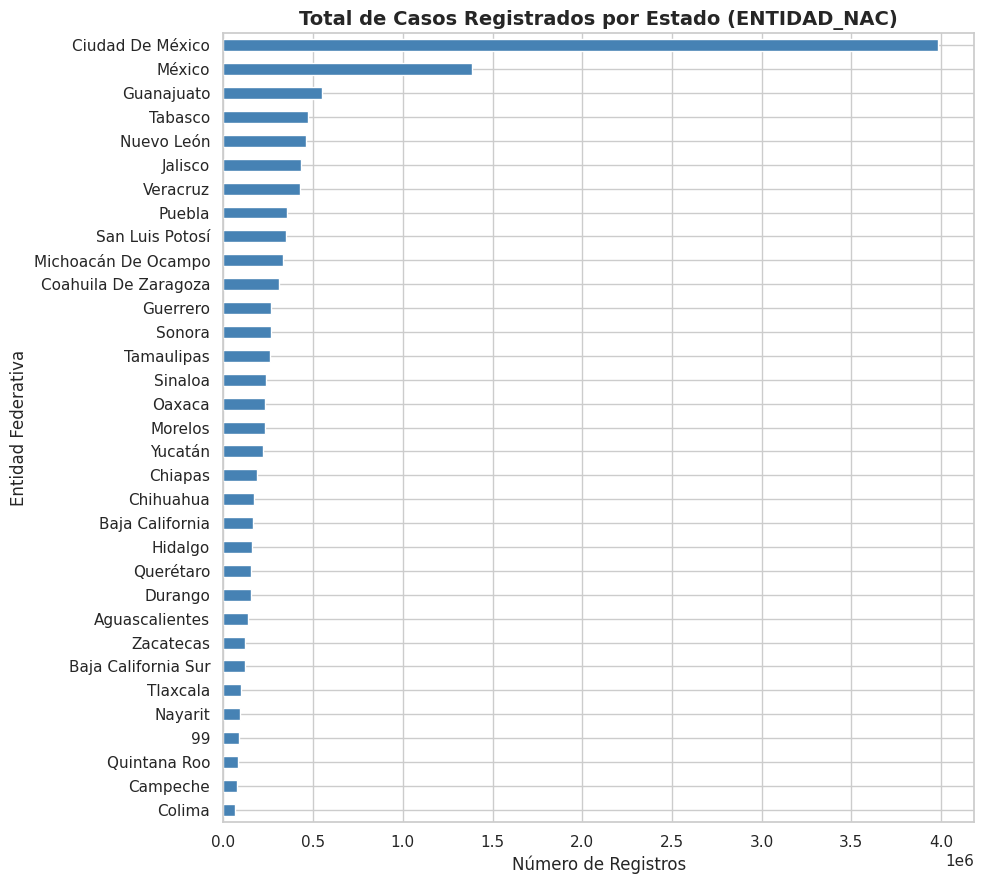

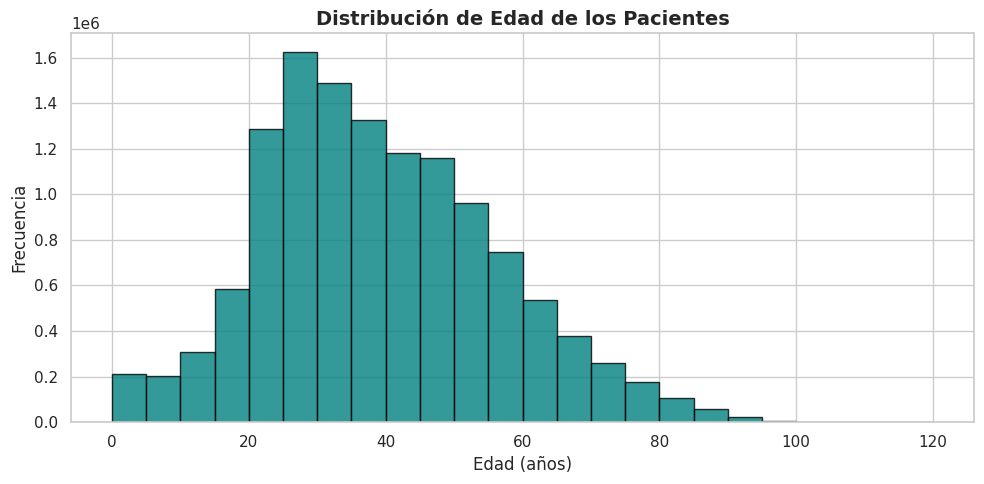

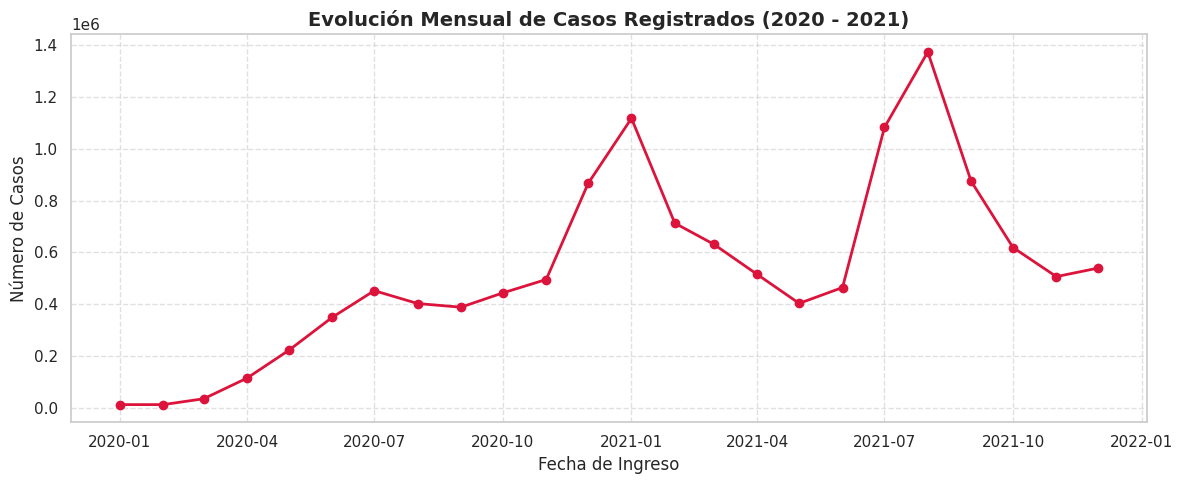

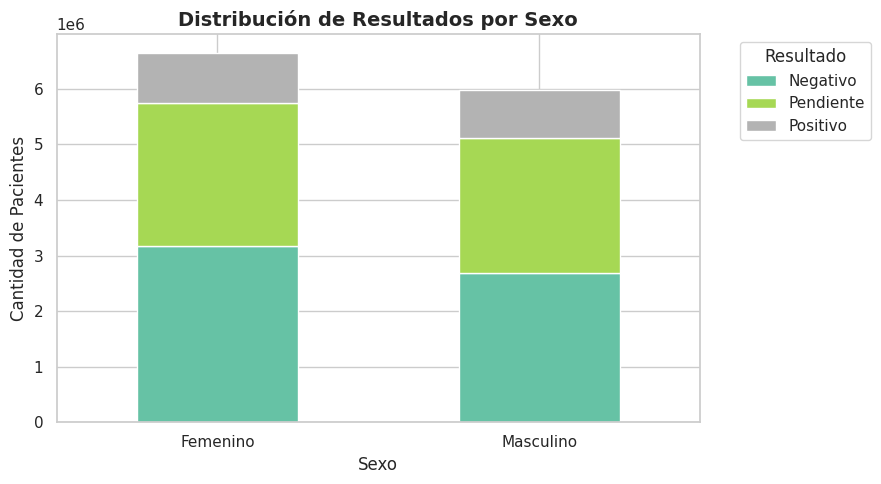

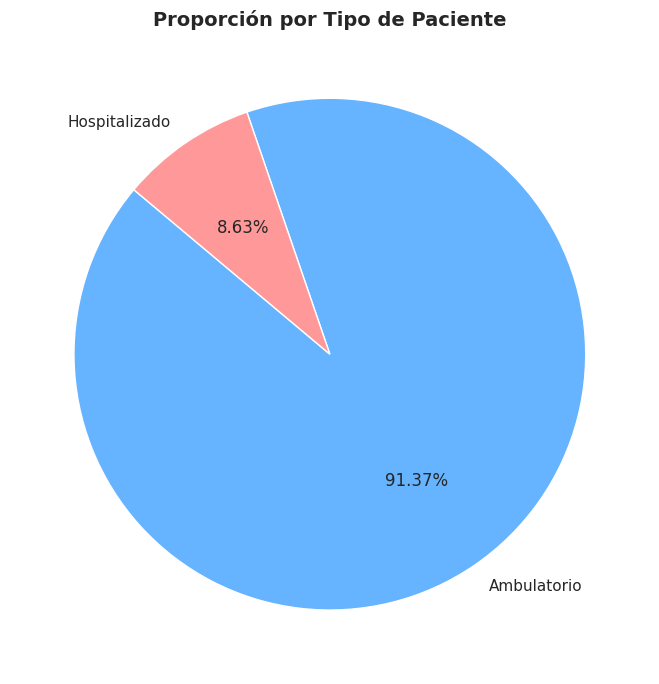

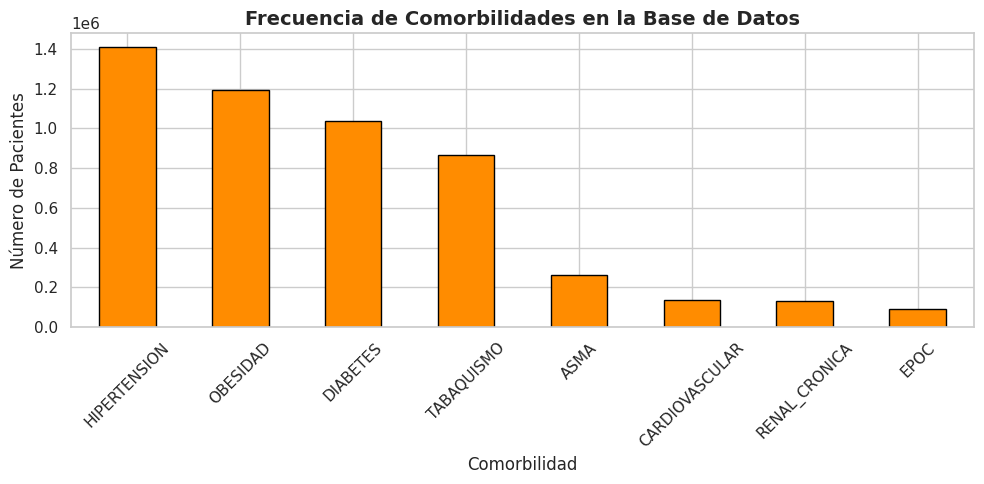

In [3]:
sns.set_theme(style="whitegrid")

# Detectar columna de estado ('ENTIDAD_RES' o 'ENTIDAD_NAC')
col_estado = 'ENTIDAD_RES' if 'ENTIDAD_RES' in df.columns else 'ENTIDAD_NAC'

# 1. Gráfico de barras horizontal por estado
plt.figure(figsize=(10, 9))
conteo_estados = df[col_estado].value_counts().sort_values(ascending=True)
conteo_estados.plot(kind='barh', color='steelblue')
plt.title(f'Total de Casos Registrados por Estado ({col_estado})', fontsize=14, fontweight='bold')
plt.xlabel('Número de Registros')
plt.ylabel('Entidad Federativa')
plt.tight_layout()
plt.show()

# 2. Histograma por edad
plt.figure(figsize=(10, 5))
edades_validas = df[(df['EDAD'] >= 0) & (df['EDAD'] <= 120)]['EDAD']
plt.hist(edades_validas, bins=24, color='teal', edgecolor='black', alpha=0.8)
plt.title('Distribución de Edad de los Pacientes', fontsize=14, fontweight='bold')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

# 3. Gráfico de líneas por fecha para mostrar la evolución de casos
plt.figure(figsize=(12, 5))
fechas = pd.to_datetime(df['FECHA_INGRESO'], errors='coerce')
evolucion = fechas.dt.to_period('M').value_counts().sort_index()
evolucion.index = evolucion.index.to_timestamp()
plt.plot(evolucion.index, evolucion.values, marker='o', color='crimson', linewidth=2)
plt.title('Evolución Mensual de Casos Registrados (2020 - 2021)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha de Ingreso')
plt.ylabel('Número de Casos')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 4. Gráfico de barras apiladas por sexo y resultado
tabla_sexo_res = pd.crosstab(df['SEXO'], df[col_res])
tabla_sexo_res.plot(kind='bar', stacked=True, figsize=(9, 5), colormap='Set2')
plt.title('Distribución de Resultados por Sexo', fontsize=14, fontweight='bold')
plt.xlabel('Sexo')
plt.ylabel('Cantidad de Pacientes')
plt.xticks(rotation=0)
plt.legend(title='Resultado', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 5. Gráfico circular por tipo de paciente
plt.figure(figsize=(7, 7))
conteo_tipo = df['TIPO_PACIENTE'].value_counts()
plt.pie(conteo_tipo, labels=conteo_tipo.index, autopct='%1.2f%%', startangle=140, colors=['#66b3ff', '#ff9999', '#99ff99'])
plt.title('Proporción por Tipo de Paciente', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 6. Gráfico de barras por comorbilidad
comorbilidades_lista = [
    'DIABETES', 'HIPERTENSION', 'OBESIDAD', 'EPOC', 'ASMA',
    'INMUSUPR', 'RENAL_CRONICA', 'CARDIOVASCULAR', 'TABAQUISMO'
]
comorbilidades = [c for c in comorbilidades_lista if c in df.columns]

conteo_comorb = {c: (df[c].astype(str).str.lower() == 'si').sum() for c in comorbilidades}
serie_comorb = pd.Series(conteo_comorb).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
serie_comorb.plot(kind='bar', color='darkorange', edgecolor='black')
plt.title('Frecuencia de Comorbilidades en la Base de Datos', fontsize=14, fontweight='bold')
plt.xlabel('Comorbilidad')
plt.ylabel('Número de Pacientes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
total_general = len(df)
print(f"Total general de casos en la base: {total_general:,}\n")

# 1. Probabilidad Simple: P(Comorbilidad)
prob_simple = []
for c in comorbilidades:
    total_c = (df[c].astype(str).str.lower() == 'si').sum()
    p_c = total_c / total_general
    prob_simple.append({
        'Comorbilidad': c,
        'Total Pacientes': total_c,
        'Probabilidad Simple P(C)': round(p_c, 6),
        'Porcentaje (%)': round(p_c * 100, 2)
    })

df_prob_simple = pd.DataFrame(prob_simple).sort_values(by='Probabilidad Simple P(C)', ascending=False)
print("=== PROBABILIDAD SIMPLE POR COMORBILIDAD ===")
display(df_prob_simple)

# 2. Probabilidad Condicional: P(Comorbilidad | Entidad Federativa)
prob_condicional = pd.DataFrame(index=sorted(df[col_estado].dropna().unique()))
for c in comorbilidades:
    es_si = (df[c].astype(str).str.lower() == 'si')
    prob_condicional[c] = es_si.groupby(df[col_estado]).mean().round(4)

print(f"\n=== PROBABILIDAD CONDICIONAL P(Comorbilidad | {col_estado}) ===")
display(prob_condicional)

Total general de casos en la base: 12,634,194

=== PROBABILIDAD SIMPLE POR COMORBILIDAD ===


,Comorbilidad,Total Pacientes,Probabilidad Simple P(C),Porcentaje (%)
1,HIPERTENSION,1407779,0.111426,11.14
2,OBESIDAD,1193021,0.094428,9.44
0,DIABETES,1038459,0.082194,8.22
7,TABAQUISMO,865162,0.068478,6.85
4,ASMA,263855,0.020884,2.09
6,CARDIOVASCULAR,134410,0.010639,1.06
5,RENAL_CRONICA,129874,0.010280,1.03
3,EPOC,92446,0.007317,0.73



=== PROBABILIDAD CONDICIONAL P(Comorbilidad | ENTIDAD_NAC) ===


,DIABETES,HIPERTENSION,OBESIDAD,EPOC,ASMA,RENAL_CRONICA,CARDIOVASCULAR,TABAQUISMO
99,0.0243,0.0511,0.0416,0.0039,0.0269,0.0031,0.0087,0.0485
Aguascalientes,0.0757,0.1167,0.1043,0.0089,0.0252,0.0157,0.0123,0.0764
Baja California,0.0850,0.1426,0.1410,0.0080,0.0368,0.0097,0.0152,0.0706
Baja California Sur,0.0718,0.1107,0.1257,0.0033,0.0289,0.0072,0.0105,0.0551
Campeche,0.0879,0.1249,0.1362,0.0070,0.0270,0.0104,0.0104,0.0444
Chiapas,0.0824,0.1086,0.0920,0.0066,0.0211,0.0109,0.0100,0.0408
Chihuahua,0.1056,0.1645,0.1210,0.0120,0.0320,0.0139,0.0187,0.0860
Ciudad De México,0.0651,0.0869,0.0764,0.0047,0.0187,0.0059,0.0083,0.0914
Coahuila De Zaragoza,0.0946,0.1255,0.0801,0.0055,0.0186,0.0114,0.0114,0.0611
Colima,0.0802,0.1124,0.1456,0.0062,0.0286,0.0138,0.0103,0.0612


Z1 (para X=2000): -0.5042
Z2 (para X=3000): 0.8964
Probabilidad P(2000 <= X <= 3000): 0.5079 (50.79%)


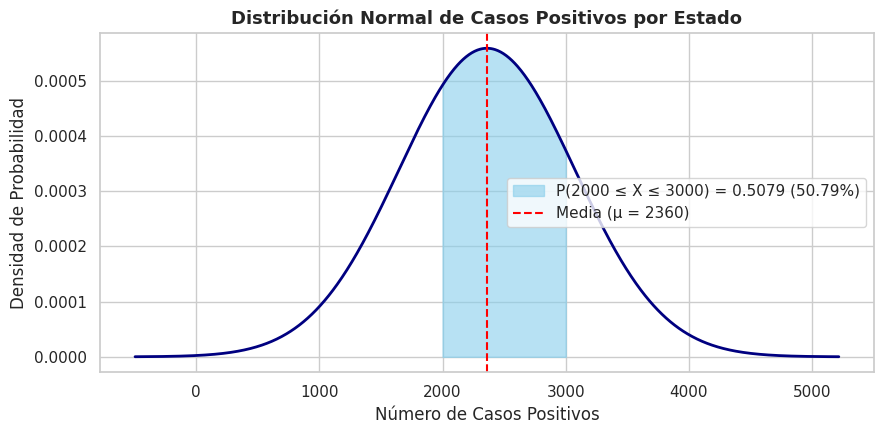

In [5]:
mu = 2360
sigma = 714
x1, x2 = 2000, 3000

z1 = (x1 - mu) / sigma
z2 = (x2 - mu) / sigma
probabilidad = norm.cdf(x2, loc=mu, scale=sigma) - norm.cdf(x1, loc=mu, scale=sigma)

print(f"Z1 (para X=2000): {z1:.4f}")
print(f"Z2 (para X=3000): {z2:.4f}")
print(f"Probabilidad P(2000 <= X <= 3000): {probabilidad:.4f} ({probabilidad*100:.2f}%)")

# Gráfica de la curva normal sombreada
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y = norm.pdf(x, mu, sigma)

plt.figure(figsize=(9, 4.5))
plt.plot(x, y, color='navy', linewidth=2)
x_fill = np.linspace(x1, x2, 500)
plt.fill_between(x_fill, norm.pdf(x_fill, mu, sigma), color='skyblue', alpha=0.6,
                 label=f'P(2000 ≤ X ≤ 3000) = {probabilidad:.4f} ({probabilidad*100:.2f}%)')
plt.axvline(mu, color='red', linestyle='--', label=f'Media (μ = {mu})')
plt.title('Distribución Normal de Casos Positivos por Estado', fontsize=13, fontweight='bold')
plt.xlabel('Número de Casos Positivos')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.tight_layout()
plt.show()

## Interpretación General de Resultados

Al analizar los 12,634,194 registros de la base de datos de COVID-19 correspondientes a 2020 y 2021, se observa que del total de pruebas registradas, el 14.05% (1,774,708 casos) salieron positivas, el 46.33% (5,853,547) negativas y el 39.62% (5,005,939) quedaron como pendientes. En la gráfica de evolución mensual se nota claramente cómo subieron los casos en dos momentos fuertes: uno en enero de 2021 (pasando el millón de registros) y otro pico aún más alto en agosto de 2021, cerca de 1.4 millones.

En cuanto a los datos demográficos y por estado, la Ciudad de México y el Estado de México concentran por mucho la mayor cantidad de registros, seguidos de Guanajuato, Tabasco y Nuevo León, lo cual tiene sentido por la cantidad de población en esas zonas. Por edad, la mayoría de los pacientes tienen entre 25 y 45 años, con el punto más alto alrededor de los 25 a 30 años. También se registró una mayor cantidad de mujeres que de hombres en las pruebas, además de 122,583 pacientes embarazadas (0.97%) y 35,240 indígenas (0.28%). Respecto a la gravedad, el 91.37% de los pacientes fueron atendidos de forma ambulatoria y solo el 8.63% requirió hospitalización.

En el análisis de probabilidades de comorbilidades a nivel general (considerando las 8 disponibles en el archivo proporcionado, ya que la columna de inmunosupresión `INMUSUPR` no viene incluida en la base de datos), las más frecuentes fueron la hipertensión (11.14%), la obesidad (9.44%), la diabetes (8.22%) y el tabaquismo (6.85%), mientras que enfermedades como el asma, problemas cardiovasculares, insuficiencia renal o EPOC tuvieron porcentajes mucho más bajos. Al revisar la probabilidad condicional por entidad (`ENTIDAD_NAC`), se ve que estados como Zacatecas (17.84%), Sinaloa (16.56%) y Chihuahua (16.45%) presentan las proporciones más altas de hipertensión entre sus registros. Por último, en el ejercicio de distribución normal con media de 2,360 y desviación estándar de 714, la probabilidad de que un estado tenga entre 2,000 y 3,000 casos positivos resultó de 0.5079 (50.79%), lo que muestra que poco más de la mitad de los estados caen dentro de ese rango.

---

## Conclusión Personal

Con este proyecto pude aplicar en un caso real lo que vimos durante el semestre en Probabilidad y Estadística, desde sacar frecuencias y porcentajes básicos hasta calcular probabilidades condicionales y áreas bajo la curva normal. Al principio fue un reto manejar un archivo tan pesado con más de 12 millones de filas, pero usar Google Colab junto con pandas y matplotlib facilitó mucho el procesamiento y la creación de las gráficas para entender mejor el comportamiento de los datos.